# 05 · Budget variance
**Where to Invest: Microsoft Growth Investment Analysis**

Goal: explain where actuals missed or beat plan, and why. Actual vs budget by fiscal year, quarter, segment and
cost type, then a bridge from budgeted to actual operating income: **volume → price/mix → cost**.

Tools: SQL (DuckDB) views built in `03_profitability.ipynb`; Python (pandas) to read them; matplotlib for the charts.

> **Synthetic data, calibrated to Microsoft's published results.** Generated by `data/generate.py`: totals by
> segment and quarter are close to Microsoft's reported figures; every record underneath them is invented.

In [1]:
import os
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

# Works whether the notebook is run from the project root or from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)

# The database and its views were built in 03_profitability.ipynb; here we only read them
con = duckdb.connect("data/finance.duckdb", read_only=True)


def billions(value):
    """Format USD as $12.3B."""
    return f"${value / 1_000_000_000:,.1f}B"


FAV, UNFAV, NEUTRAL = "#1F7A3E", "#C00000", "#1F4E79"   # better than plan, worse than plan, actuals

## 1. Plan vs actual by fiscal year

Only months with actuals are compared, so FY27 is year to date (Jul–Sep 2026). The planning export has no FY24
budget. FY26 also has a mid-year **Forecast 6+6** (6 months actual + 6 months forecast).

In [2]:
annual = con.sql("""
    SELECT fiscal_year,
           SUM(budget_usd)       FILTER (WHERE line_item = 'Revenue')  AS budget_revenue_usd,
           SUM(actual_usd)       FILTER (WHERE line_item = 'Revenue')  AS actual_revenue_usd,
           SUM(forecast_6_6_usd) FILTER (WHERE line_item = 'Revenue')  AS forecast_6_6_revenue_usd,
           SUM(budget_usd)       FILTER (WHERE line_item <> 'Revenue') AS budget_cost_usd,
           SUM(actual_usd)       FILTER (WHERE line_item <> 'Revenue') AS actual_cost_usd
    FROM v_budget_vs_actual
    GROUP BY fiscal_year
    ORDER BY fiscal_year
""").df()
annual["budget_operating_income_usd"] = annual["budget_revenue_usd"] - annual["budget_cost_usd"]
annual["actual_operating_income_usd"] = annual["actual_revenue_usd"] - annual["actual_cost_usd"]
annual["revenue_variance_pct"] = annual["actual_revenue_usd"] / annual["budget_revenue_usd"] - 1
annual["cost_variance_pct"] = annual["actual_cost_usd"] / annual["budget_cost_usd"] - 1
annual["operating_income_variance_usd"] = annual["actual_operating_income_usd"] - annual["budget_operating_income_usd"]
annual["period"] = annual["fiscal_year"].where(annual["fiscal_year"] != "FY27", "FY27 YTD")

annual.style.format({
    **{c: billions for c in annual.columns if c.endswith("_usd")},
    "revenue_variance_pct": "{:+.1%}",
    "cost_variance_pct": "{:+.1%}",
}, na_rep="–").hide(axis="index")

fiscal_year,budget_revenue_usd,actual_revenue_usd,forecast_6_6_revenue_usd,budget_cost_usd,actual_cost_usd,budget_operating_income_usd,actual_operating_income_usd,revenue_variance_pct,cost_variance_pct,operating_income_variance_usd,period
FY25,$273.9B,$280.5B,–,$146.9B,$151.4B,$126.9B,$129.1B,+2.4%,+3.1%,$2.1B,FY25
FY26,$330.1B,$330.5B,$329.4B,$170.7B,$174.3B,$159.4B,$156.2B,+0.1%,+2.1%,$-3.2B,FY26
FY27,$90.0B,$92.0B,–,$47.1B,$47.7B,$42.9B,$44.3B,+2.2%,+1.3%,$1.4B,FY27 YTD


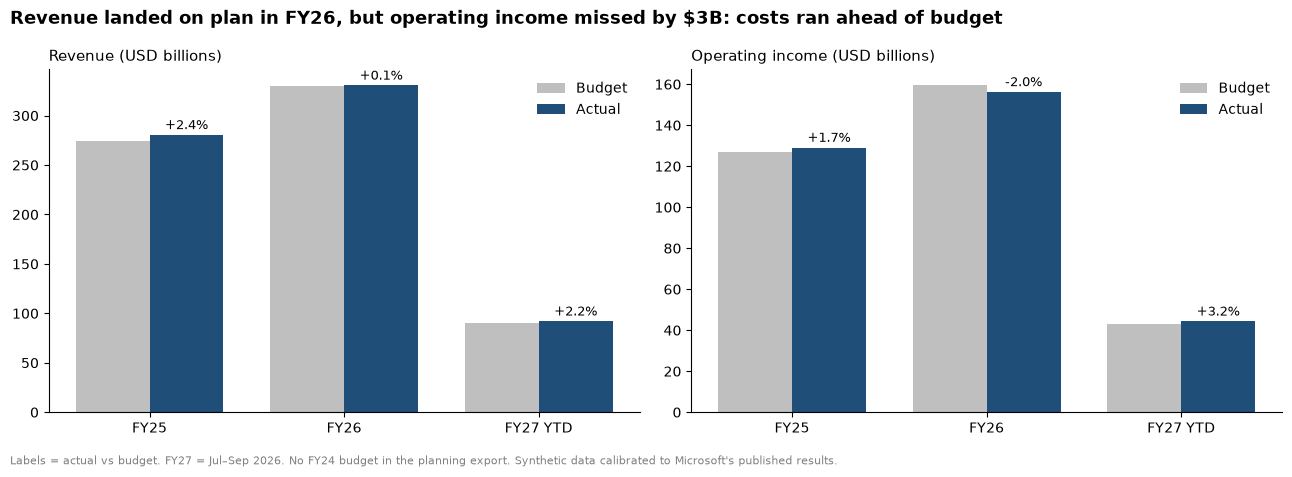

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
x = range(len(annual))
w = 0.38
for ax, metric, title in [(axes[0], "revenue", "Revenue"), (axes[1], "operating_income", "Operating income")]:
    budget = annual[f"budget_{metric}_usd"] / 1e9
    actual = annual[f"actual_{metric}_usd"] / 1e9
    ax.bar([p - w / 2 for p in x], budget, w, color="#BFBFBF", label="Budget")
    bars = ax.bar([p + w / 2 for p in x], actual, w, color=NEUTRAL, label="Actual")
    ax.bar_label(bars, labels=[f"{v:+.1%}" for v in actual / budget - 1], padding=2, fontsize=9)
    ax.set_xticks(list(x))
    ax.set_xticklabels(annual["period"])
    ax.set_title(f"{title} (USD billions)", loc="left", fontsize=11)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)
fig.suptitle("Revenue landed on plan in FY26, but operating income missed by $3B: costs ran ahead of budget",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.text(0.01, -0.03, "Labels = actual vs budget. FY27 = Jul–Sep 2026. No FY24 budget in the planning export. "
         "Synthetic data calibrated to Microsoft's published results.", fontsize=8, color="grey")
plt.tight_layout()
plt.show()

**Findings.**
- **FY25:** revenue beat budget by 2.4% ($280.5B vs $273.9B) and operating income by 1.7%.
- **FY26:** revenue landed on plan (+0.1%, $330.5B), but operating income missed by **$3.2B (−2.0%)**: actual
  costs were above budget, mainly R&D (+6.2%, $34.6B vs $32.6B). The mid-year Forecast 6+6 ($329.4B revenue) was
  close to the outcome.
- **FY27 year to date:** back above plan: revenue +2.2% ($92.0B vs $90.0B), operating income +3.2%.

## 2. Quarter by quarter

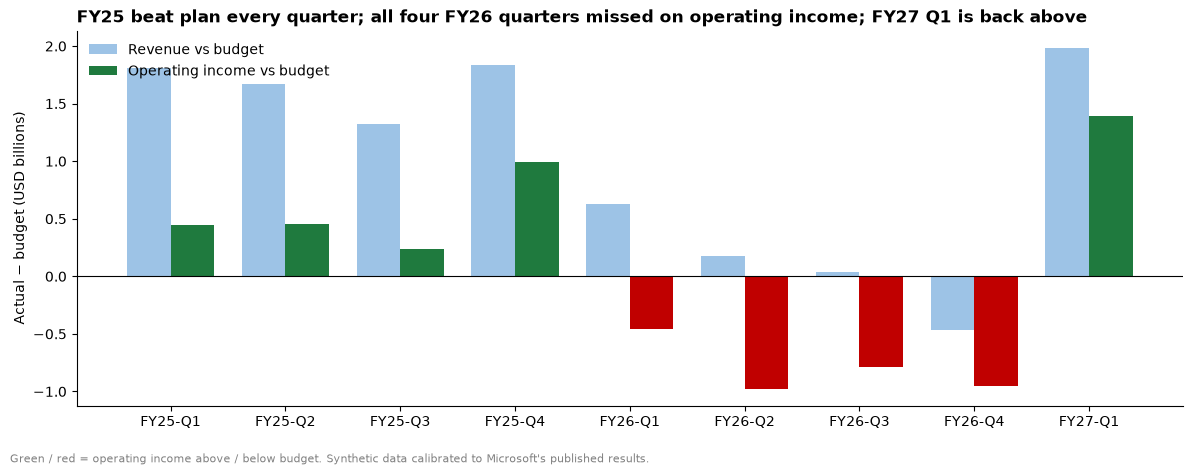

fiscal_year_quarter,revenue_usd,budget_revenue_usd,operating_income_usd,budget_operating_income_usd,revenue_vs_budget_usd,operating_income_vs_budget_usd
FY25-Q1,$65.3B,$63.5B,$29.1B,$28.7B,$1.8B,$0.4B
FY25-Q2,$69.2B,$67.6B,$31.6B,$31.2B,$1.7B,$0.5B
FY25-Q3,$69.7B,$68.4B,$32.3B,$32.1B,$1.3B,$0.2B
FY25-Q4,$76.2B,$74.4B,$36.0B,$35.0B,$1.8B,$1.0B
FY26-Q1,$77.3B,$76.7B,$36.0B,$36.4B,$0.6B,$-0.5B
FY26-Q2,$80.9B,$80.8B,$38.0B,$39.0B,$0.2B,$-1.0B
FY26-Q3,$82.6B,$82.5B,$39.1B,$39.9B,$0.0B,$-0.8B
FY26-Q4,$89.7B,$90.1B,$43.2B,$44.1B,$-0.5B,$-1.0B
FY27-Q1,$92.0B,$90.0B,$44.3B,$42.9B,$2.0B,$1.4B


In [4]:
quarters = con.sql("""
    SELECT fiscal_year_quarter, revenue_usd, budget_revenue_usd, operating_income_usd, budget_operating_income_usd,
           revenue_vs_budget_usd, operating_income_vs_budget_usd
    FROM v_kpi_quarter
    WHERE budget_revenue_usd IS NOT NULL
    ORDER BY quarter_start
""").df()

fig, ax = plt.subplots(figsize=(12, 4.5))
x = range(len(quarters))
w = 0.38
ax.bar([p - w / 2 for p in x], quarters["revenue_vs_budget_usd"] / 1e9, w, color="#9DC3E6", label="Revenue vs budget")
oi = quarters["operating_income_vs_budget_usd"] / 1e9
ax.bar([p + w / 2 for p in x], oi, w, color=[FAV if v >= 0 else UNFAV for v in oi], label="Operating income vs budget")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(list(x))
ax.set_xticklabels(quarters["fiscal_year_quarter"])
ax.set_ylabel("Actual − budget (USD billions)")
ax.legend(frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("FY25 beat plan every quarter; all four FY26 quarters missed on operating income; FY27 Q1 is back above",
             loc="left", fontsize=12, fontweight="bold")
fig.text(0.01, -0.04, "Green / red = operating income above / below budget. "
         "Synthetic data calibrated to Microsoft's published results.", fontsize=8, color="grey")
plt.tight_layout()
plt.show()

quarters.style.format({c: billions for c in quarters.columns if c.endswith("_usd")}).hide(axis="index")

**Findings.** Every FY25 quarter beat plan on revenue and operating income. In FY26 revenue stayed close to plan
(+$0.6B in Q1 down to −$0.5B in Q4), but operating income missed in all four quarters (−$0.5B to −$1.0B): the
miss is a cost story, not a demand story. FY27 Q1 beat plan by $2.0B on revenue and $1.4B on operating income.

## 3. Where the FY26 variance sits: segment × line item

Actual vs budget for each segment and line item. Colour shows whether the variance is favourable (more revenue
or less cost than plan, green) or unfavourable (red).

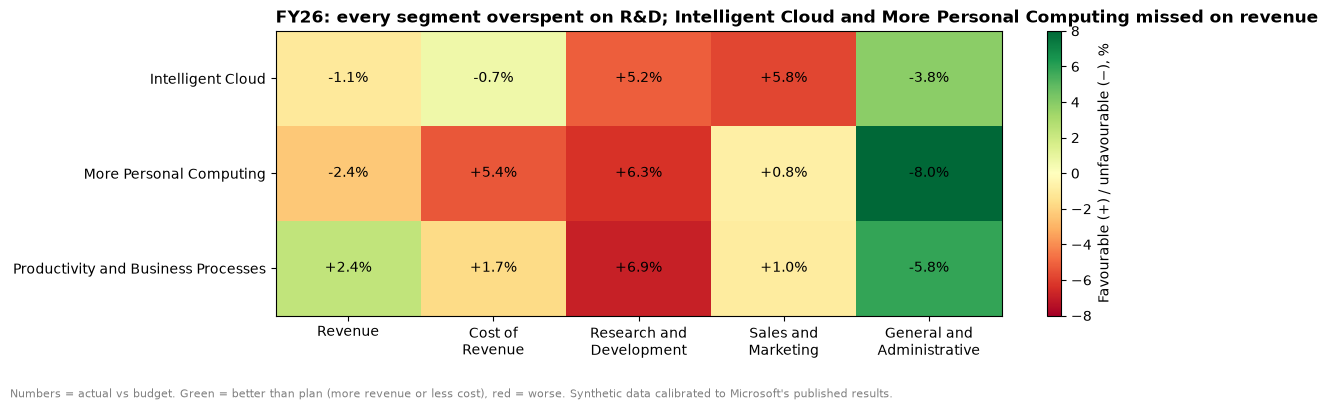

In [5]:
detail = con.sql("""
    SELECT segment, line_item, SUM(actual_usd) AS actual_usd, SUM(budget_usd) AS budget_usd
    FROM v_budget_vs_actual
    WHERE fiscal_year = 'FY26'
    GROUP BY segment, line_item
""").df()
detail["variance_pct"] = detail["actual_usd"] / detail["budget_usd"] - 1
# favourable = positive: more revenue, or less cost, than budget
detail["favourable_pct"] = detail["variance_pct"].where(detail["line_item"] == "Revenue", -detail["variance_pct"])

line_order = ["Revenue", "Cost of Revenue", "Research and Development", "Sales and Marketing",
              "General and Administrative"]
heat = detail.pivot(index="segment", columns="line_item", values="favourable_pct")[line_order]
raw = detail.pivot(index="segment", columns="line_item", values="variance_pct")[line_order]

fig, ax = plt.subplots(figsize=(12, 3.8))
im = ax.imshow(heat.values * 100, cmap="RdYlGn", vmin=-8, vmax=8, aspect="auto")
ax.set_xticks(range(len(line_order)))
ax.set_xticklabels([label.replace(" and ", " and\n").replace("Cost of ", "Cost of\n") for label in line_order])
ax.set_yticks(range(len(heat.index)))
ax.set_yticklabels(heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f"{raw.values[i, j]:+.1%}", ha="center", va="center", fontsize=10)
fig.colorbar(im, ax=ax, label="Favourable (+) / unfavourable (−), %")
ax.set_title("FY26: every segment overspent on R&D; Intelligent Cloud and More Personal Computing missed on revenue",
             loc="left", fontsize=12, fontweight="bold")
fig.text(0.01, -0.06, "Numbers = actual vs budget. Green = better than plan (more revenue or less cost), red = worse. "
         "Synthetic data calibrated to Microsoft's published results.", fontsize=8, color="grey")
plt.tight_layout()
plt.show()

**Findings (FY26).**
- **R&D ran 5%–7% over budget in all three segments**, the largest and most consistent overspend.
- **Revenue:** Productivity and Business Processes beat plan (+2.4%); Intelligent Cloud (−1.1%) and More Personal
  Computing (−2.4%) missed.
- More Personal Computing also overspent on cost of revenue (+5.4%).
- G&A came in 4%–8% under budget everywhere, but it is too small to offset the rest.

## 4. Operating-income bridge: budget → volume → price/mix → cost → actual

The plan has no unit volumes, so the budget is turned into units at last year's average price per unit (p0):
- **Volume** = (actual units − budget units) × p0 = actual units × p0 − budget revenue
- **Price/mix** = actual revenue − actual units × p0 (price changes and a richer or poorer product mix)
- **Cost** = budget costs − actual costs (positive = under budget)

The four steps add up exactly to actual operating income. All amounts are in USD, so there is no separate FX step.

Bridge reconciles: largest difference 0.00 USD


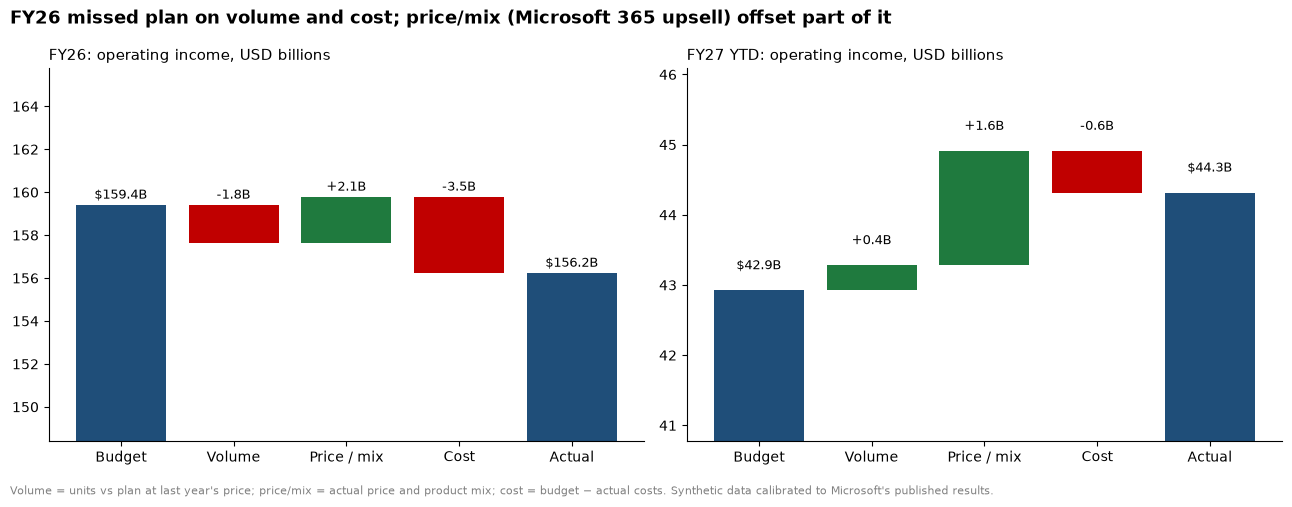

period,budget_oi,volume,price_mix,cost,actual_oi
FY26,$159.4B,$-1.8B,$2.1B,$-3.5B,$156.2B
FY27 YTD,$42.9B,$0.4B,$1.6B,$-0.6B,$44.3B


In [6]:
bridge = con.sql("""
    SELECT period,
           SUM(budget_operating_income_usd) AS budget_oi,
           SUM(volume_effect_usd)           AS volume,
           SUM(price_mix_effect_usd)        AS price_mix,
           SUM(cost_effect_usd)             AS cost,
           SUM(actual_operating_income_usd) AS actual_oi
    FROM v_budget_bridge
    GROUP BY period
    ORDER BY period
""").df()

# The bridge must reconcile: budget + volume + price/mix + cost = actual
difference = (bridge["budget_oi"] + bridge["volume"] + bridge["price_mix"] + bridge["cost"] - bridge["actual_oi"]).abs().max()
print(f"Bridge reconciles: largest difference {difference:,.2f} USD")


def waterfall(ax, row, title):
    """Waterfall from budget to actual operating income (USD billions)."""
    steps = [("Budget", row["budget_oi"], "total"), ("Volume", row["volume"], "step"),
             ("Price / mix", row["price_mix"], "step"), ("Cost", row["cost"], "step"),
             ("Actual", row["actual_oi"], "total")]
    running = 0
    for i, (label, value, kind) in enumerate(steps):
        v = value / 1e9
        if kind == "total":
            ax.bar(i, v, color=NEUTRAL)
            ax.text(i, v + 0.3, f"${v:,.1f}B", ha="center", fontsize=9)
            running = v
        else:
            bottom = running if v >= 0 else running + v
            ax.bar(i, abs(v), bottom=bottom, color=FAV if v >= 0 else UNFAV)
            ax.text(i, max(running, running + v) + 0.3, f"{v:+.1f}B", ha="center", fontsize=9)
            running += v
    ax.set_xticks(range(len(steps)))
    ax.set_xticklabels([s[0] for s in steps])
    ax.set_ylim(min(row["budget_oi"], row["actual_oi"]) / 1e9 * 0.95,
                max(row["budget_oi"], row["actual_oi"]) / 1e9 * 1.04)
    ax.set_title(title, loc="left", fontsize=11)
    ax.spines[["top", "right"]].set_visible(False)


fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, (_, row) in zip(axes, bridge.iterrows()):
    waterfall(ax, row, f"{row['period']}: operating income, USD billions")
fig.suptitle("FY26 missed plan on volume and cost; price/mix (Microsoft 365 upsell) offset part of it",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.text(0.01, -0.03, "Volume = units vs plan at last year's price; price/mix = actual price and product mix; "
         "cost = budget − actual costs. Synthetic data calibrated to Microsoft's published results.",
         fontsize=8, color="grey")
plt.tight_layout()
plt.show()

bridge.style.format({c: billions for c in bridge.columns if c != "period"}).hide(axis="index")

**Findings.**
- **FY26:** budget $159.4B → volume −$1.8B → price/mix +$2.1B → cost −$3.5B → actual **$156.2B**. Fewer units
  than planned and higher costs explain the miss; a better price/mix recovered part of it.
- **FY27 year to date:** budget $42.9B → volume +$0.4B → price/mix +$1.6B → cost −$0.6B → actual **$44.3B**.
  Price/mix is again the main positive driver.
- The y-axis does not start at zero, to make the steps readable; the totals are labelled.

## 5. Which product lines drive the FY26 variance?

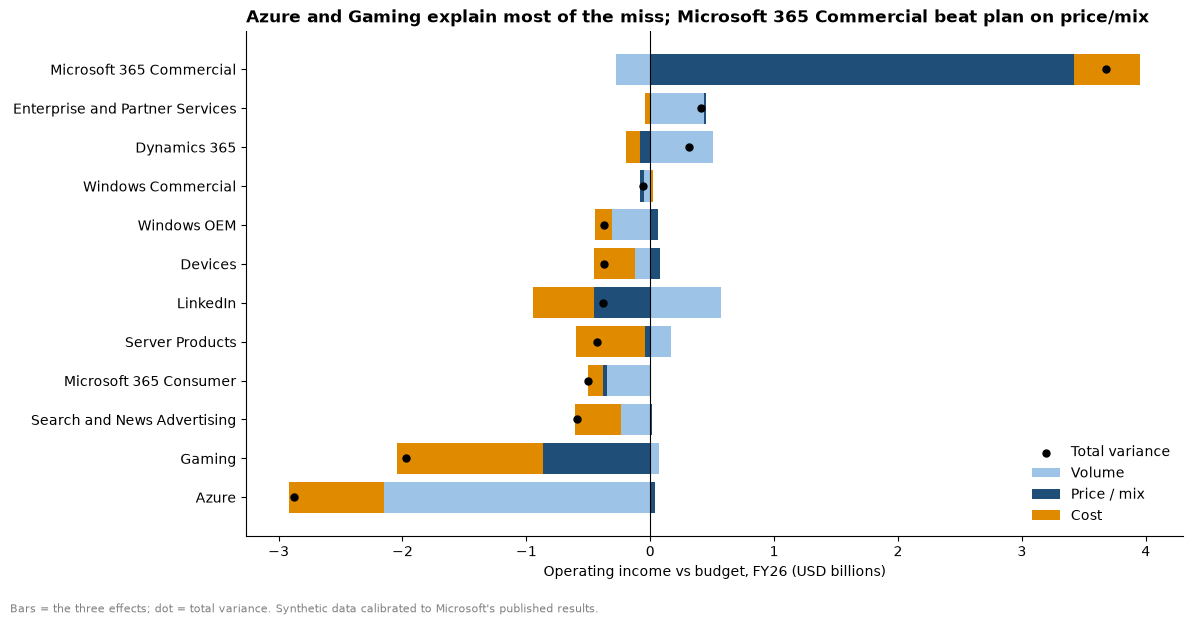

product_line,budget_operating_income_usd,volume_effect_usd,price_mix_effect_usd,cost_effect_usd,actual_operating_income_usd,variance_usd
Azure,$39.5B,$-2.1B,$0.0B,$-0.8B,$36.7B,$-2.9B
Gaming,$4.0B,$0.1B,$-0.9B,$-1.2B,$2.1B,$-2.0B
Search and News Advertising,$5.4B,$-0.2B,$0.0B,$-0.4B,$4.8B,$-0.6B
Microsoft 365 Consumer,$6.0B,$-0.4B,$-0.0B,$-0.1B,$5.5B,$-0.5B
Server Products,$18.3B,$0.2B,$-0.0B,$-0.6B,$17.8B,$-0.4B
LinkedIn,$7.9B,$0.6B,$-0.5B,$-0.5B,$7.5B,$-0.4B
Devices,$-0.3B,$-0.1B,$0.1B,$-0.3B,$-0.6B,$-0.4B
Windows OEM,$8.4B,$-0.3B,$0.1B,$-0.1B,$8.0B,$-0.4B
Windows Commercial,$5.2B,$-0.1B,$-0.0B,$0.0B,$5.2B,$-0.1B
Dynamics 365,$4.0B,$0.5B,$-0.1B,$-0.1B,$4.3B,$0.3B


In [7]:
lines = con.sql("""
    SELECT product_line, budget_operating_income_usd, volume_effect_usd, price_mix_effect_usd, cost_effect_usd,
           actual_operating_income_usd,
           actual_operating_income_usd - budget_operating_income_usd AS variance_usd
    FROM v_budget_bridge
    WHERE period = 'FY26'
    ORDER BY variance_usd
""").df()

fig, ax = plt.subplots(figsize=(12, 6))
y = range(len(lines))
effects = [("volume_effect_usd", "Volume", "#9DC3E6"),
           ("price_mix_effect_usd", "Price / mix", "#1F4E79"),
           ("cost_effect_usd", "Cost", "#E08A00")]
pos_left = [0.0] * len(lines)     # positive effects stack to the right of zero
neg_left = [0.0] * len(lines)     # negative effects stack to the left
for col, label, color in effects:
    values = (lines[col] / 1e9).tolist()
    lefts = [pos_left[i] if v >= 0 else neg_left[i] for i, v in enumerate(values)]
    ax.barh(y, values, left=lefts, color=color, label=label)
    for i, v in enumerate(values):
        if v >= 0:
            pos_left[i] += v
        else:
            neg_left[i] += v
ax.scatter(lines["variance_usd"] / 1e9, y, color="black", zorder=3, s=25, label="Total variance")
ax.set_yticks(list(y))
ax.set_yticklabels(lines["product_line"])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Operating income vs budget, FY26 (USD billions)")
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Azure and Gaming explain most of the miss; Microsoft 365 Commercial beat plan on price/mix",
             loc="left", fontsize=12, fontweight="bold")
fig.text(0.01, -0.03, "Bars = the three effects; dot = total variance. "
         "Synthetic data calibrated to Microsoft's published results.", fontsize=8, color="grey")
plt.tight_layout()
plt.show()

lines.style.format({c: billions for c in lines.columns if c.endswith("_usd")}).hide(axis="index")

**Findings (FY26).**
- **Azure −$2.9B:** mostly volume (−$2.2B: $105.7B revenue vs $107.8B planned) plus −$0.8B of cost overrun.
  Azure grew 43%, but the plan expected even more, which fits the capacity-constrained picture in notebook 04.
- **Gaming −$2.0B:** price/mix (−$0.9B) and costs (−$1.2B), consistent with its Deprioritise position in notebook 03.
- **Microsoft 365 Commercial +$3.7B:** almost all price/mix (+$3.4B): customers moving to higher-priced plans.
- Dynamics 365 (+$0.3B) and Enterprise and Partner Services (+$0.4B) beat plan on volume.

## Summary
- FY25 beat plan; **FY26 missed operating income by $3.2B (−2.0%)** with revenue on plan; FY27 Q1 is back above
  plan (+$1.4B).
- The FY26 miss is a **cost** story (R&D 5%–7% over budget in every segment) plus **Azure volume** below an
  aggressive plan; Microsoft 365 Commercial's price/mix offset part of it.
- **For FY27 planning:** budget R&D at the run-rate actually spent, plan Azure volume against available
  capacity (notebook 04), and keep tracking Microsoft 365 price/mix as the main upside.
- **Next:** `06_forecast.ipynb`: Q2 FY27 revenue with 80% and 95% intervals, back-tested on the last two quarters.

In [8]:
con.close()   # releases data/finance.duckdb so the next notebook can open it